# The decompilation flow, box by box

> **In short.**
> * **The question.** A block of a QEC program does a logical gate $L = E\,;P\,;E^\dagger$ on the encoded qubits ($E$ is the encoder of the code). How does the tool find out which gate?
> * **The method.** L. Yeh's flow chart (Fig. 19 of the paper). If $L$ is Clifford, bring it to a normal form and read the gate there, with no matrix. If not, split $L$ into a Clifford part $\mathcal{U}$ followed by phases, and name it by its small matrix.
> * **What the tool does.** `LogicalAction.path()` says which branch of the chart a gate takes. `tableau()` and `normal_form()` give the Clifford answer. `clifford_part()` gives $\mathcal{U}$ and the phases. Questions 2 and 3 (`branches()`, `verdict()`) follow the chart by default.
> * **The test.** On every block of four programs, the chart's way and the old way (every class of runs as a matrix) give the same answers.

| step | program | box of the chart | functions |
|---|---|---|---|
| 1 | fold-transversal Hadamard, whole program | Clifford, isometry: iAPNF | `path`, `tableau`, `normal_form` |
| 2 | a stage of the $T$ injection that measures | Clifford, projector | `path`, `normal_form` |
| 3 | transversal $T$ on the $[[15,1,3]]$ code | not Clifford: $\mathcal{U}$ and phases | `clifford_part` |
| 4 | $T$ injection, whole program | not Clifford | `clifford_part`, `verdict` |
| 5 | every block of four programs | all of them | `with_route`, `named_by` |

In [1]:
import sys
sys.path.insert(0, '..')
import interactive_fold_h_3d as fold_h          # the fold-transversal Hadamard of FoldH.ipynb
from pyzx.circuit import Circuit
from pyzx.circuit.gates import T
from pyzx.css import generate_css_encoder_graph
from pyzx.linalg import Mat2
from zxqec.codes import code_of, logical_action
from zxqec.gpf import same_map
from zxqec.qprogram import program_from_stim
from zxqec.spacetime import draw_graph
from tests.programs import steane_t_injection
%matplotlib inline

## 1. A Clifford gate: the fold-transversal Hadamard

**What we do.** We build the fold-transversal Hadamard on the $[[9,1,3]]$ surface code (as in `FoldH.ipynb`), take the logical gate of the whole program, and ask which branch of the chart it takes.

In [2]:
p = fold_h.build_program()
act = p.logical_action()
print(act.path())

Clifford isometry: named from the stabilizers of its Choi state (tableau, iAPNF)


**What you see.** The gate is Clifford and an isometry, so it takes the left branch of the chart: no matrix is needed.

**What we do.** We read its *tableau*: where $L$ sends the logical $X$ and the logical $Z$. The tool reads it from the stabilizers of the Choi state of $L$ (its input bent into an output), by Gaussian elimination. Then we name it.

In [3]:
tab = act.tableau()
print(tab)
print()
name, correction = tab.name()
print("name:", name)
print("correction:", correction)

Clifford tableau: 1 -> 1 logical qubit(s)
  X0 -> (-1)^(c[0] + c[1] + c[2] + c[3] + c[4])Z    Z0 -> (-1)^(c[26] + c[29] + c[32])X

name: H
correction: X^(c[0] + c[1] + c[2] + c[3] + c[4]) Z^(c[26] + c[29] + c[32]) on 0


**What you see.** $X \to Z$ and $Z \to X$: a Hadamard. The signs are sums of measurement results. They are the Pauli frame of every run at once: the correction is $X$ to the power of the first sum and $Z$ to the power of the second.

**What we do.** We compare with Question 3 (`verdict`), which looks at the classes of runs one by one.

In [4]:
print(act.verdict())

deterministic up to a Pauli frame: every run implements H followed by a Pauli correction (X, Y, Z, none) that the outcomes determine


**What you see.** The same answer: $H$ in every run, followed by one of four Paulis that the results decide.

**What we do.** We ask for the normal form of the chart's box ("iAPNF if isometry") and draw it.

isometry AP normal form: 1 input(s) -> 1 output(s)
  U_I   phases 0: (c[0] + c[1] + c[2] + c[3] + c[4]) pi; CZ none; H on inputs [0]; X-CZ none
  core  input X-spiders: input 0 -> outputs {0}
        Z-check X-spiders: none
  U_O   phases 0: (c[26] + c[29] + c[32]) pi; CZ none


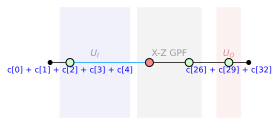

In [5]:
nf = act.normal_form()
print(nf)
nf.draw(figsize=(4, 2))

**What you see.** The isometry AP normal form of $L$: one input, one output, and the Hadamard in its first layer ($U_I$). The phases that depend on the results are the Pauli frame again.

**What we do.** We check how the classes of runs were named: `named_by` counts the classes named from the Choi state (`flow`) and by a matrix (`matrix`).

In [6]:
print(act.named_by)

{'flow': 4, 'matrix': 0}


**What you see.** Every class was named from the stabilizers. No matrix was built.

## 2. A Clifford block that measures: a stage of the $T$ injection

**What we do.** We take the $T$ injection into the Steane code and ask, for each stage, which branch it takes and what it does.

In [7]:
t_inj = steane_t_injection()
for i in range(t_inj.num_stages):
    stage = t_inj.logical_action(0, i)
    print("stage", i, "|", stage.path())
    print("         ", stage.verdict().splitlines()[0])

stage 0 | Clifford isometry: named from the stabilizers of its Choi state (tableau, iAPNF)
          deterministic: every run implements I


stage 1 | not Clifford: a Clifford isometry followed by phase effects; named by its matrix


          deterministic: every run implements I on qubits 0-6 (x) prepares T|+> on qubit 10


stage 2 | Clifford isometry: named from the stabilizers of its Choi state (tableau, iAPNF)
          deterministic: every run implements I
stage 3 | Clifford isometry: named from the stabilizers of its Choi state (tableau, iAPNF)
          deterministic: every run implements I


stage 4 | Clifford isometry: named from the stabilizers of its Choi state (tableau, iAPNF)
          deterministic: every run implements CNOT(0->1)
stage 5 | Clifford, not an isometry: named from the stabilizers of its Choi state (AP form)
          deterministic up to a Pauli frame: every run implements I on qubits 0-6 (x) Z measurement on qubits 7-13 followed by a Pauli correction (none, outcome flipped by X on qubits 7-13) that the outcomes determine
stage 6 | not Clifford: a Clifford isometry followed by phase effects; named by its matrix
          not deterministic: the operation depends on the outcomes (I when c[6] + c[7] + c[8] + c[9] + c[10] + c[11] + c[12] = 0; S when c[6] + c[7] + c[8] + c[9] + c[10] + c[11] + c[12] = 1)


**What you see.** Most stages are Clifford isometries. Stages 1 and 6 hold $T$ gates, so they are not Clifford. Stage 5 measures seven qubits: it is Clifford but not an isometry. That is the chart's other Clifford box ("projector NF if projector").

**What we do.** We ask stage 5 for its normal form.

In [8]:
measuring = t_inj.logical_action(0, 5)
print(measuring.normal_form())
print()
print(measuring.verdict())
print(measuring.named_by)

reduced AP form on 3 variables: 0, in0, in1
  rows of B (X-spiders): {0, in0}, pivot 0; {in1}, pivot in1 (phase c[6] + c[7] + c[9] pi)
  free variables: in0
  phases: none
  CZ: none



deterministic up to a Pauli frame: every run implements I on qubits 0-6 (x) Z measurement on qubits 7-13 followed by a Pauli correction (none, outcome flipped by X on qubits 7-13) that the outcomes determine
{'flow': 2, 'matrix': 0}


**What you see.** For a map that is not an isometry, the tool gives the reduced AP form of its Choi state: the parity rows on the outputs (`0`) and the bent inputs (`in0`, `in1`), with signs from the results. We use it in place of the chart's projector NF. The stage is named from the same stabilizers, with no matrix: the identity on one code block, and a $Z$ measurement of the other.

## 3. A non-Clifford gate: transversal $T$ on the $[[15,1,3]]$ code

**What we do.** We build the $[[15,1,3]]$ code from its four $X$ checks, put $T$ on all 15 qubits, and take the logical gate between the encoder and its inverse.

In [9]:
sx = Mat2([[1,0,1,0,1,0,1,0,1,0,1,0,1,0,1], [0,1,1,0,0,1,1,0,0,1,1,0,0,1,1],
           [0,0,0,1,1,1,1,0,0,0,0,1,1,1,1], [0,0,0,0,0,0,0,1,1,1,1,1,1,1,1]])
enc, _ = generate_css_encoder_graph(sx, Mat2([[1] * 15]), 'Z-X')
enc.auto_detect_io()
code15 = code_of(enc)
layer = Circuit(15)
for q in range(15):
    layer.add_gate(T(q))
act15 = logical_action(layer.to_graph(), code15, code15, via='encoder')
print(act15.path())

not Clifford: a Clifford isometry followed by phase effects; named by its matrix


**What you see.** The gate is not Clifford, so it takes the right branch.

**What we do.** We follow that branch: take the non-Clifford phases off as extra outputs ("unfuse into lollipops"), and read the Clifford part $\mathcal{U}$ that is left as its tableau and its iAPNF.

Clifford part U: 1 -> 1 + 1 outputs, followed by phase effects
  output 1: Z phase 7/4 pi
  U is a Clifford isometry; Clifford tableau: 1 -> 2 logical qubit(s)
    X0 -> +XX    Z0 -> +ZI
    stabilizer +ZZ

isometry AP normal form: 1 input(s) -> 2 output(s)
  U_I   phases none; CZ none; H on inputs none; X-CZ none
  core  input X-spiders: input 0 -> outputs {1}
        Z-check X-spiders: outputs {0, 1}
  U_O   phases none; CZ none


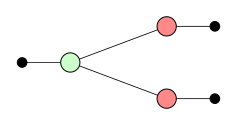

In [10]:
cp = act15.clifford_part()
print(cp)
print()
print(cp.normal_form)
draw_graph(cp.clifford, time_axis=False, show_time=False, figsize=(4, 2))

**What you see.** $\mathcal{U}$ copies the logical qubit onto a second output ($Z \mapsto Z \otimes I$, stabilizer $ZZ$). One phase effect, $7\pi/4$, sits on that copy. A $7\pi/4$ phase on a copy of the logical qubit is a logical $T^\dagger$.

**What we do.** We plug the phase back onto $\mathcal{U}$ and check that this is the same map as $L$. Then we ask for the name, which the tool gets from the small matrix.

In [11]:
print("U followed by the phase is L:", same_map(act15.graph, cp.to_graph()))
print(act15.verdict())
print(act15.named_by)

U followed by the phase is L: True
deterministic: every run implements T^dag
{'flow': 0, 'matrix': 1}


**What you see.** Plugging the phase back gives $L$ again. The gate is $T^\dagger$, named by its $2 \times 2$ matrix (`named_by` counts one class named by a matrix).

## 4. A whole program with a $T$ gate: the $T$ injection

**What we do.** We take the logical gate of the whole $T$ injection and its Clifford part.

In [12]:
whole = t_inj.logical_action()
print(whole.path())
cp_t = whole.clifford_part()
print(len(cp_t.phases), "phase effects:", [(str(a), kind) for a, kind in cp_t.phases])
print("U is a Clifford isometry:", cp_t.is_isometry)
print(whole.verdict())
print(whole.named_by)

not Clifford: a Clifford isometry followed by phase effects; named by its matrix
5 phase effects: [('5/4', 'Z'), ('5/4', 'Z'), ('5/4', 'Z'), ('1/4', 'Z'), ('1/4', 'Z')]
U is a Clifford isometry: True
deterministic: every run implements T
{'flow': 0, 'matrix': 2}


**What you see.** The right branch again. Here the adding up inside the reduction (the chart's "triorthogonal rewrites") leaves five phase effects, not one, and $\mathcal{U}$ is still a Clifford isometry. The tool names the gate, $T$ in every run, from the small matrix of each class.

## 5. The test: the chart's way and the matrix way agree

**What we do.** For every block of four programs (the whole program and each stage), we compute Questions 2 and 3 twice: the chart's way (the default) and the old way, with every class of runs as a matrix (`with_route('matrix')`). We compare the name, the correction, whether it is unitary and how each class relates to the first, and count the classes named each way.

In [13]:
cultivation = program_from_stim(open('circuits/cultivation/d3_cultivation.stim').read())[0]
programs = {'fold-transversal H': p, 'T injection': t_inj,
            'T injection, no correction': steane_t_injection(correct=False), 'cultivation, d = 3': cultivation}
print("{:28s} {:>6s} {:>14s} {:>16s} {:>10s}".format("program", "blocks", "classes: flow", "classes: matrix", "same?"))
for title, prog in programs.items():
    actions = [prog.logical_action()] + [prog.logical_action(0, i) for i in range(prog.num_stages)]
    same = all([(b.operation, b.correction, b.unitary, b.same_as_reference, b.conditions) for b in a.branches()]
               == [(b.operation, b.correction, b.unitary, b.same_as_reference, b.conditions)
                   for b in a.with_route('matrix').branches()] for a in actions)
    print("{:28s} {:6d} {:14d} {:16d} {:>10s}".format(title, len(actions), sum(a.named_by['flow'] for a in actions),
                                                       sum(a.named_by['matrix'] for a in actions), str(same)))

program                      blocks  classes: flow  classes: matrix      same?


fold-transversal H                9             16                0       True


T injection                       8              6                5       True


T injection, no correction        7              6                3       True


cultivation, d = 3                6              2               21       True


**What you see.** In every block both ways give the same answers. The Clifford classes, including the blocks that measure, are named with no matrix. Matrices are only built where a $T$ phase is left in the diagram, or where a block has no logical qubit at all (its map is a number).

## What this shows

| box of the chart | function | here |
|---|---|---|
| Clifford, isometry: iAPNF | `tableau`, `normal_form` | fold-transversal $H$: $H$, with the Pauli frame as a formula in the results |
| Clifford, projector | `normal_form` (AP form of the Choi state) | stage 5 of the $T$ injection: a $Z$ measurement, no matrix |
| unfuse into lollipops; iAPNF of $\mathcal{U}$ | `clifford_part` | $[[15,1,3]]$: $\mathcal{U}$ copies the logical qubit, one $7\pi/4$ phase, so $T^\dagger$ |
| optimization, triorthogonal rewrites | inside `reduce_gpf` (adding up the gadgets) | $T$ injection: five phases left; named $T$ by its matrix |
| the whole chart | `branches`, `verdict` (default) | same answers as the matrix way on every block |

One difference from the chart: the tool adds up the gadgets inside the reduction, before it splits off $\mathcal{U}$; the chart does it after. Both give the same $L$.